**1. Importing the libraries**
  

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px 
import plotly.io as pio 
pio.renderers.default = "svg"

**2. Importing the dataset**

In [2]:
raw_df = pd.read_csv('zomato.csv')

In [3]:
raw_df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


**3. Getting Basic Information about the Dataset**

In [4]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [5]:
raw_df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


**4. Cleaning the Dataset**

In [6]:
raw_df.drop(['url', 'phone','address'], axis = 1, inplace=True) 

In [7]:
raw_df.head() 

,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


**b. Removing the Null Record**

In [8]:
raw_df.isnull().sum()

name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

**c. Converting the DataTypes of numerical columns to numeric dataype**

In [9]:
raw_df['rate'] = raw_df['rate'].str.replace('/5', '', regex=False)
raw_df['rate'] = raw_df['rate'].replace(['NEW', '-'], '0')
raw_df['rate'] = pd.to_numeric(raw_df['rate'], errors='coerce')
raw_df['rate']

0        4.1
1        4.1
2        3.8
3        3.7
4        3.8
        ... 
51712    3.6
51713    NaN
51714    NaN
51715    4.3
51716    3.4
Name: rate, Length: 51717, dtype: float64

In [10]:
raw_df['rate']=raw_df['rate'].astype(float)
raw_df['rate']

0        4.1
1        4.1
2        3.8
3        3.7
4        3.8
        ... 
51712    3.6
51713    NaN
51714    NaN
51715    4.3
51716    3.4
Name: rate, Length: 51717, dtype: float64

In [11]:
raw_df['rate'] = raw_df['rate'].fillna(0)

In [12]:
raw_df['rate'].unique()

array([4.1, 3.8, 3.7, 3.6, 4.6, 4. , 4.2, 3.9, 3.1, 3. , 3.2, 3.3, 2.8,
       4.4, 4.3, 0. , 2.9, 3.5, 2.6, 3.4, 4.5, 2.5, 2.7, 4.7, 2.4, 2.2,
       2.3, 4.8, 4.9, 2.1, 2. , 1.8])

In [13]:
raw_df['dish_liked'] = raw_df['dish_liked'].fillna('Not Available')

In [14]:
raw_df['approx_cost(for two people)'].unique()

<ArrowStringArray>
[  '800',   '300',   '600',   '700',   '550',   '500',   '450',   '650',
   '400',   '900',   '200',   '750',   '150',   '850',   '100', '1,200',
   '350',   '250',   '950', '1,000', '1,500', '1,300',   '199',    '80',
 '1,100',   '160', '1,600',   '230',   '130',    '50',   '190', '1,700',
     nan, '1,400',   '180', '1,350', '2,200', '2,000', '1,800', '1,900',
   '330', '2,500', '2,100', '3,000', '2,800', '3,400',    '40', '1,250',
 '3,500', '4,000', '2,400', '2,600',   '120', '1,450',   '469',    '70',
 '3,200',    '60',   '560',   '240',   '360', '6,000', '1,050', '2,300',
 '4,100', '5,000', '3,700', '1,650', '2,700', '4,500',   '140']
Length: 71, dtype: str

In [15]:
raw_df['approx_cost(for two people)'] = raw_df['approx_cost(for two people)'].str.replace(',', '', regex=False)

In [16]:
raw_df['approx_cost(for two people)'] = pd.to_numeric(
    raw_df['approx_cost(for two people)'], errors='coerce'
)

In [17]:
raw_df.dropna(subset=['approx_cost(for two people)'], inplace=True)

In [18]:
raw_df['book_table'] = raw_df['book_table'].map({
    'Yes': 1,
    'No': 0
})

In [19]:
raw_df['online_order'] = raw_df['online_order'].map({
    'Yes': 1,
    'No': 0
})

In [20]:
raw_df['location'] = raw_df['location'].fillna(raw_df['location'].mode()[0], inplace=True)

C:\Users\abina_a2cu98a\AppData\Local\Temp\ipykernel_10384\657208570.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  raw_df['location'] = raw_df['location'].fillna(raw_df['location'].mode()[0], inplace=True)


In [21]:
raw_df['cuisines'] = raw_df['cuisines'].fillna('Not Available')

In [22]:
raw_df['rest_type'] = raw_df['rest_type'].fillna(raw_df['rest_type'].mode()[0], inplace=True)

C:\Users\abina_a2cu98a\AppData\Local\Temp\ipykernel_10384\3077981970.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  raw_df['rest_type'] = raw_df['rest_type'].fillna(raw_df['rest_type'].mode()[0], inplace=True)


In [23]:
raw_df.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
reviews_list                   0
menu_item                      0
listed_in(type)                0
listed_in(city)                0
dtype: int64

**h. Removing Duplicate record**

In [24]:
raw_df[raw_df.duplicated()] 

,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
596,My Tea House,1,1,0.0,0,Banashankari,Casual Dining,Not Available,"Continental, Asian, North Indian, Tea",500.0,"[('Rated 4.0', ""RATED\n So apparently I visit...","['MTH Signature Soup', 'Minestrone Veg', 'Broc...",Dine-out,Banashankari
2235,Shiv Sagar,0,0,3.6,10,Bannerghatta Road,Food Court,Not Available,"South Indian, Beverages",400.0,"[('Rated 4.0', 'RATED\n It was yesterday I vi...",[],Dine-out,Bannerghatta Road
4339,Biryani Treat,0,0,0.0,0,Bellandur,Quick Bites,Not Available,Biryani,400.0,[],[],Delivery,Bellandur
7599,Nawab Di Biryani,1,0,0.0,0,Whitefield,"Takeaway, Delivery",Not Available,"Biryani, Mughlai",400.0,"[('Rated 4.0', 'RATED\n Ordered paneer tikka ...","['Paneer Tikka Biryani', 'Veg Lucknowi Biryani...",Delivery,Brookefield
9342,Healthy Parathawala,1,0,0.0,0,BTM,Quick Bites,Not Available,North Indian,200.0,[],"['Aloo Paratha Chole Combo', 'Gobi Paratha Cho...",Delivery,BTM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46553,House Of Candy,1,0,0.0,0,Malleshwaram,Confectionery,Not Available,Desserts,200.0,[],[],Delivery,Rajajinagar
49193,Sri Ganesh Juice Junction,1,0,3.5,6,Bellandur,Beverage Shop,Not Available,"Juices, Fast Food",200.0,"[('Rated 4.0', 'RATED\n A perfect place to dr...",[],Delivery,Sarjapur Road
49432,Biryani Treat,0,0,0.0,0,Bellandur,Quick Bites,Not Available,Biryani,400.0,[],[],Delivery,Sarjapur Road
50405,House Of Candy,1,0,0.0,0,Whitefield,Confectionery,Not Available,Desserts,200.0,[],[],Delivery,Whitefield


In [25]:
raw_df = raw_df.drop_duplicates() 

**4. Copying the cleaned data into a new DataFrame**

In [26]:
zomato_df = raw_df.copy()

In [27]:
 zomato_df.head() 

,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,Jalsa,1,1,4.1,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,Spice Elephant,1,0,4.1,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,San Churro Cafe,1,0,3.8,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,Addhuri Udupi Bhojana,0,0,3.7,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,Grand Village,0,0,3.8,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


**5. Performing Exploratory Data Analysis**

**Q1) calculate avg rating of each resturant**

In [28]:
zomato_df.groupby('name')['rate'].mean()

name
#FeelTheROLL                                    3.400
#L-81 Cafe                                      3.900
#Vibes Restro                                   0.000
#refuel                                         3.700
'Brahmins' Thatte Idli                          0.000
                                                ...  
late100                                         0.000
nu.tree                                         3.775
re:cess - Hilton Bangalore Embassy GolfLinks    4.100
repEAT Hub                                      0.000
sCoolMeal                                       0.000
Name: rate, Length: 8756, dtype: float64

<Axes: xlabel='name'>

C:\Anaconda3\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Anaconda3\Lib\site-packages\IPython\core\events.py:100: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


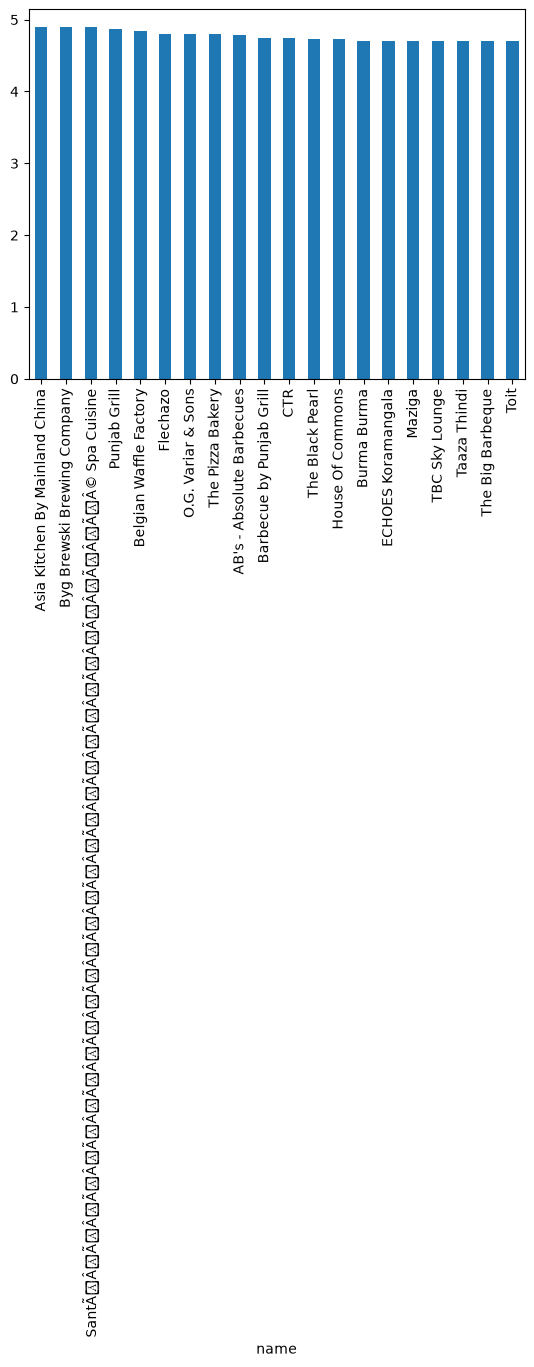

In [29]:
zomato_df.groupby('name')['rate'].mean().nlargest(20).plot.bar()

In [30]:
zomato_df_rate=zomato_df.groupby('name')['rate'].mean().to_frame()
zomato_df_rate=zomato_df_rate.reset_index()
zomato_df_rate.columns=['restaurant','rating']
zomato_df_rate.head(10)

,restaurant,rating
0,#FeelTheROLL,3.4
1,#L-81 Cafe,3.9
2,#Vibes Restro,0.0
3,#refuel,3.7
4,'Brahmins' Thatte Idli,0.0
5,1 Fahreheit,0.0
6,1000 B.C,3.2
7,100ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ°C,3.7
8,11 to 11 Express Biriyanis,3.5
9,1131 Bar + Kitchen,4.5


**Q2) Which are the top restaurant chains in Bangaluru?**

In [31]:
chains = zomato_df['name'].value_counts()[:20]
chains

name
Cafe Coffee Day      96
Onesta               85
Just Bake            73
Empire Restaurant    71
Five Star Chicken    70
Kanti Sweets         68
Petoo                66
Polar Bear           65
Baskin Robbins       64
Pizza Hut            62
Sweet Truth          60
Domino's Pizza       60
Beijing Bites        60
KFC                  60
Subway               60
McDonald's           59
Smoor                59
Chai Point           58
Faasos               57
Lassi Shop           56
Name: count, dtype: int64

In [32]:
%pip install --upgrade plotly

Note: you may need to restart the kernel to use updated packages.


7.1.0


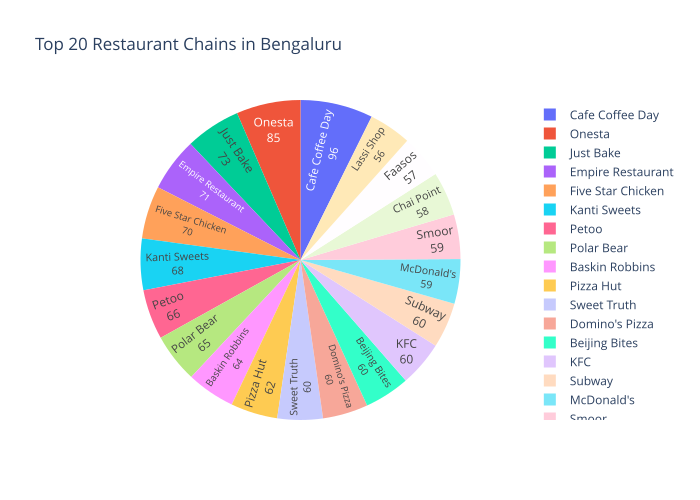

In [33]:
import plotly
import plotly.express as px

print(plotly.__version__)

fig = px.pie(
    names=chains.index,
    values=chains.values,
    title='Top 20 Restaurant Chains in Bengaluru'
)

fig.update_traces(
    textposition='inside',
    textinfo='label+value'
)

fig.show()

**Q3) How many Restaurants Accepting Online Orders?**

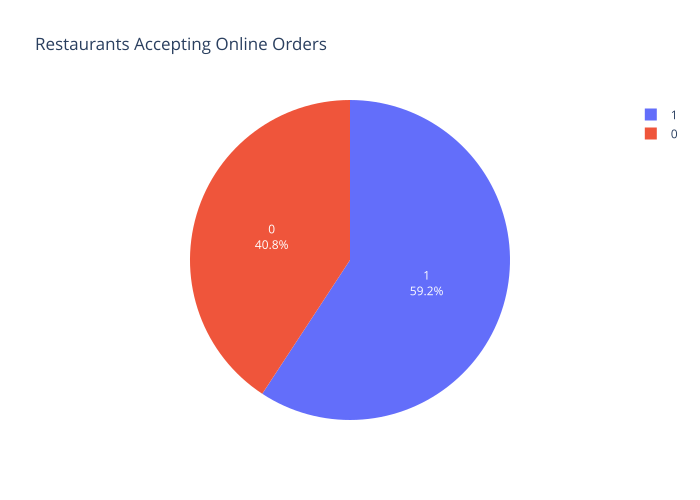

In [34]:
import plotly.express as px

x = zomato_df['online_order'].value_counts()

fig = px.pie(
    names=x.index,
    values=x.values,
    title='Restaurants Accepting Online Orders'
)

fig.update_traces(
    textposition='inside',
    textinfo='label+percent'
)

fig.show()

**Q4) What is highest voted restaurant?**

<Axes: xlabel='name'>

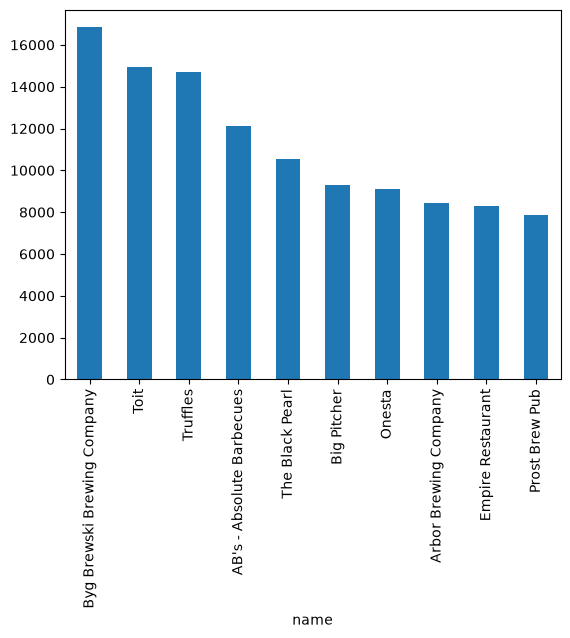

In [35]:
zomato_df.groupby('name')['votes'].max().nlargest(10).plot.bar()

**Q5) Total restaurants at different locations of Bengalore?**

In [36]:
zomato_df.groupby('location')['name'].unique()

location
BTM                  [Sankranthi Veg Restaurant, Hearts Unlock Cafe...
Banashankari         [Jalsa, Spice Elephant, San Churro Cafe, Addhu...
Banaswadi            [Cafe Nibras, The Sanctuary, Crunch Pizzas, 9 ...
Bannerghatta Road    [Deja Vu Resto Bar, Fattoush, Empire Restauran...
Basavanagudi         [Grand Village, Timepass Dinner, Srinathji's C...
                                           ...                        
West Bangalore       [FreshMenu, Fit Dish Fetish, Garden City Mobil...
Whitefield           [Imperio Cafe, Night Diaries, LocalHost, AB's ...
Wilson Garden        [Tree Top, Sahana's (Nati Style), Karavali Kol...
Yelahanka            [Prashanth Naati Corner, Red Chillies Curries ...
Yeshwantpur          [Chef's Bank, New Agarwal Bhavan, Fishing Boat...
Name: name, Length: 93, dtype: object

In [37]:
restaurant=[]
location=[]
for key,location_df in zomato_df.groupby('location'):
    location.append(key)
    restaurant.append(len(location_df['name'].unique()))


In [38]:
df_total=pd.DataFrame(zip(location,restaurant))
df_total.columns=['location','restaurant']
df_total.set_index('location',inplace=True)
df_total.sort_values(by='restaurant').tail(10)

,restaurant
location,
Bellandur,349
Jayanagar,352
Bannerghatta Road,447
JP Nagar,501
Indiranagar,522
Marathahalli,656
HSR,681
Electronic City,695
BTM,698


<Axes: xlabel='location'>

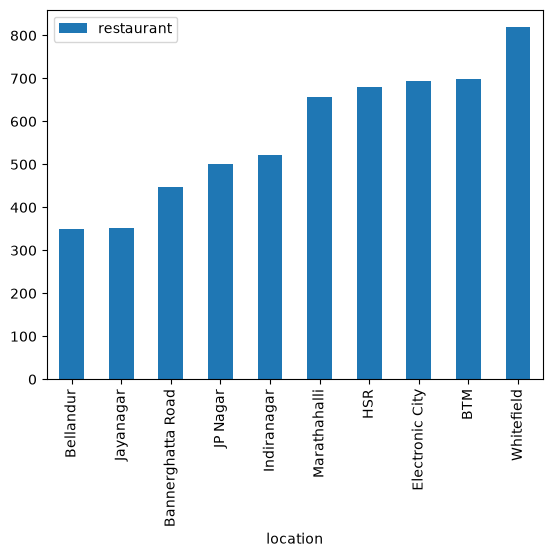

In [39]:
df_total.sort_values(by='restaurant').tail(10).plot.bar()

**Q6) Find the Top 10 most popular cuisines in Bengaluru.**

In [41]:
cuisine = zomato_df['cuisines'].str.split(',')
cuisine = cuisine.explode()
cuisine = cuisine.str.strip()
top_cuisine = cuisine.value_counts().head(10)

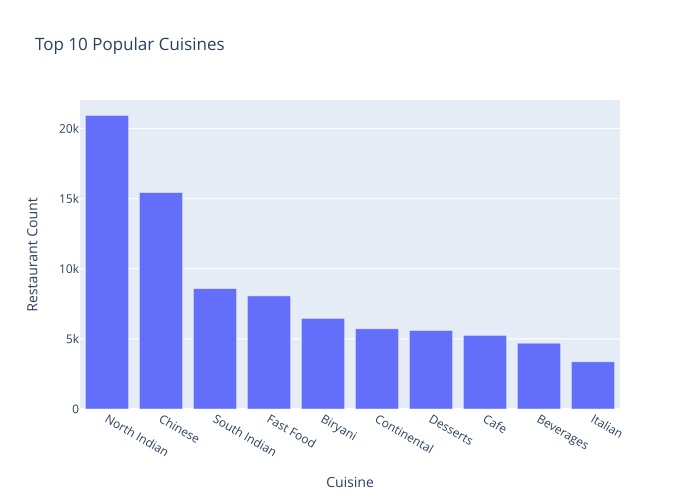

In [42]:
import plotly.express as px

fig = px.bar(
    x=top_cuisine.index,
    y=top_cuisine.values,
    title='Top 10 Popular Cuisines',
    labels={'x':'Cuisine', 'y':'Restaurant Count'}
)

fig.show()